# Phase 19 — Historical Feature Expansion & Predictive Signal Analysis

**Project:** Australian Stock Market Analytics & Return Modeling

## Objective
Expand the candidate feature set using only historical prices and benchmark data already available in the Phase 8 processed files. Audit the timing of each feature, analyze redundancy/missingness, and assess whether expanded features improve validation performance over a training-mean baseline.

**Important**
- Features are calculated per ticker from that ticker's history, using data available at the row date or earlier.
- The target remains the Phase 13 corrected `forward_return_3m` with its endpoint date.
- Do not tune features based on test performance. This phase reports validation results only.
- No model result here establishes trading profitability.

## 1. Setup and locate project files

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
RANDOM_STATE = 42

PRICE_REL = Path("data/processed/market_data/asx_company_daily_prices.csv")
BENCH_REL = Path("data/processed/market_data/asx200_benchmark_daily.csv")
TRAIN_REL = Path("data/processed/model_features/asx_3m_strict_split_train.csv")
VALID_REL = Path("data/processed/model_features/asx_3m_strict_split_validation.csv")
TEST_REL = Path("data/processed/model_features/asx_3m_strict_split_test.csv")

def locate_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        required = [PRICE_REL, TRAIN_REL, VALID_REL, TEST_REL]
        if all((p / r).exists() for r in required):
            return p
    for p in start.iterdir() if start.exists() else []:
        if p.is_dir() and all((p / r).exists() for r in [PRICE_REL, TRAIN_REL, VALID_REL, TEST_REL]):
            return p
    return None

PROJECT_ROOT = locate_root()
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate Phase 8 prices and Phase 13 split files. Run previous phases first.")

OUT = PROJECT_ROOT / "reports" / "feature_expansion"
OUT.mkdir(parents=True, exist_ok=True)
FEATURE_OUT = PROJECT_ROOT / "data" / "processed" / "expanded_features"
FEATURE_OUT.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Benchmark file available:", (PROJECT_ROOT / BENCH_REL).exists())

Project root: e:\Projects\Australian Stock Market Data Science Project
Benchmark file available: True


## 2. Load and normalize price data

In [2]:
prices = pd.read_csv(PROJECT_ROOT / PRICE_REL, low_memory=False)
prices.columns = [str(c).strip().lower() for c in prices.columns]
rename = {}
if "ticker" not in prices.columns:
    for c in ["symbol", "stock", "company_ticker"]:
        if c in prices.columns:
            rename[c] = "ticker"; break
if "date" not in prices.columns:
    for c in ["datetime", "timestamp", "trading_date"]:
        if c in prices.columns:
            rename[c] = "date"; break
prices = prices.rename(columns=rename)
if not {"ticker", "date"}.issubset(prices.columns):
    raise ValueError(f"Price data requires ticker/date. Columns: {prices.columns.tolist()}")

price_col = "adj_close" if "adj_close" in prices.columns else ("close" if "close" in prices.columns else None)
if price_col is None:
    raise ValueError("No adj_close or close price column found.")
prices["ticker"] = prices["ticker"].astype(str).str.strip().str.upper()
prices["date"] = pd.to_datetime(prices["date"], errors="coerce")
prices[price_col] = pd.to_numeric(prices[price_col], errors="coerce")
prices = prices.dropna(subset=["ticker", "date", price_col])
prices = prices[prices[price_col] > 0].sort_values(["ticker", "date"])
prices = prices.drop_duplicates(["ticker", "date"], keep="last").reset_index(drop=True)
prices["close_for_features"] = prices[price_col].astype(float)
print("Rows:", len(prices), "| Tickers:", prices["ticker"].nunique(),
      "| Dates:", prices["date"].min(), "to", prices["date"].max(),
      "| Price column:", price_col)
display(prices.head())

Rows: 65771 | Tickers: 52 | Dates: 2021-10-19 00:00:00 to 2026-10-19 00:00:00 | Price column: close


,date,close,high,low,open,volume,yahoo_symbol,ticker,close_for_features
0,2021-10-19,6.458141,6.467407,6.143110,6.143110,5232326,A2M.AX,A2M,6.458141
1,2021-10-20,6.847298,6.902892,6.485939,6.532267,15237359,A2M.AX,A2M,6.847298
2,2021-10-21,6.606391,6.847297,6.569328,6.847297,6015791,A2M.AX,A2M,6.606391
3,2021-10-22,6.384016,6.597125,6.346954,6.597125,6359080,A2M.AX,A2M,6.384016
4,2021-10-25,6.300626,6.439610,6.272829,6.393282,4083248,A2M.AX,A2M,6.300626


## 3. Engineer lagged returns, trend, and volatility features

Returns and rolling statistics are calculated within each ticker. Rolling windows include the current row's price and past observations only; no future prices are used in predictors.

In [3]:
prices = prices.sort_values(["ticker", "date"]).copy()
g = prices.groupby("ticker", sort=False)["close_for_features"]

for horizon in [1, 5, 21, 63, 126]:
    prices[f"momentum_{horizon}d"] = g.pct_change(horizon)

daily_return = g.pct_change(1)
prices["daily_return"] = daily_return

for window in [5, 21, 63]:
    prices[f"volatility_{window}d"] = (
        prices.groupby("ticker", sort=False)["daily_return"]
        .transform(lambda s: s.rolling(window, min_periods=window).std())
    )

for window in [21, 63, 126]:
    prices[f"sma_{window}d"] = (
        prices.groupby("ticker", sort=False)["close_for_features"]
        .transform(lambda s: s.rolling(window, min_periods=window).mean())
    )
    prices[f"price_to_sma_{window}d"] = (
        prices["close_for_features"] / prices[f"sma_{window}d"] - 1
    )

# Short-term reversal: negative of the previous day's return, known at the current date.
prices["previous_day_return"] = prices.groupby("ticker", sort=False)["daily_return"].shift(1)
prices["short_term_reversal_1d"] = -prices["previous_day_return"]

feature_cols_stock = [
    f"momentum_{h}d" for h in [1, 5, 21, 63, 126]
] + [
    f"volatility_{w}d" for w in [5, 21, 63]
] + [
    f"price_to_sma_{w}d" for w in [21, 63, 126]
] + ["short_term_reversal_1d"]

display(prices[["ticker", "date"] + feature_cols_stock].tail())

,ticker,date,momentum_1d,momentum_5d,momentum_21d,momentum_63d,momentum_126d,volatility_5d,volatility_21d,volatility_63d,price_to_sma_21d,price_to_sma_63d,price_to_sma_126d,short_term_reversal_1d
65766,WPR,2026-10-13,0.000000,0.019512,-0.060854,-0.122691,-0.114804,0.013290,0.013698,0.010981,-0.019994,-0.088592,-0.100579,0.014151
65767,WPR,2026-10-14,-0.014354,-0.009615,-0.061937,-0.142342,-0.134575,0.013774,0.013743,0.011010,-0.031119,-0.099544,-0.112518,-0.000000
65768,WPR,2026-10-15,0.014563,0.004808,-0.048276,-0.133389,-0.125512,0.015673,0.014257,0.011187,-0.014669,-0.084387,-0.098669,0.014354
65769,WPR,2026-10-16,-0.004785,-0.018868,-0.048582,-0.137536,-0.129696,0.011949,0.014260,0.011188,-0.017040,-0.086661,-0.102029,-0.014563
65770,WPR,2026-10-19,0.000000,-0.004785,-0.048582,-0.134016,-0.129696,0.010450,0.014260,0.011189,-0.014685,-0.084607,-0.101074,0.004785


## 4. Add benchmark features when the benchmark file exists

In [4]:
benchmark_feature_cols = []
bench_path = PROJECT_ROOT / BENCH_REL

if bench_path.exists():
    bench = pd.read_csv(bench_path, low_memory=False)
    bench.columns = [str(c).strip().lower() for c in bench.columns]
    if "date" not in bench.columns:
        for c in ["datetime", "timestamp", "trading_date"]:
            if c in bench.columns:
                bench = bench.rename(columns={c: "date"}); break
    bench_price_col = "adj_close" if "adj_close" in bench.columns else ("close" if "close" in bench.columns else None)
    if "date" in bench.columns and bench_price_col:
        bench["date"] = pd.to_datetime(bench["date"], errors="coerce")
        bench[bench_price_col] = pd.to_numeric(bench[bench_price_col], errors="coerce")
        bench = bench.dropna(subset=["date", bench_price_col]).sort_values("date")
        bench = bench.drop_duplicates("date", keep="last").reset_index(drop=True)
        bench["benchmark_daily_return"] = bench[bench_price_col].pct_change()
        for horizon in [1, 5, 21, 63, 126]:
            col = f"benchmark_return_{horizon}d"
            bench[col] = bench[bench_price_col].pct_change(horizon)
            benchmark_feature_cols.append(col)
        for window in [5, 21, 63]:
            col = f"benchmark_volatility_{window}d"
            bench[col] = bench["benchmark_daily_return"].rolling(window, min_periods=window).std()
            benchmark_feature_cols.append(col)
        bench_features = bench[["date"] + benchmark_feature_cols].copy()
        prices = prices.merge(bench_features, on="date", how="left", validate="many_to_one")
        print("Benchmark features added:", benchmark_feature_cols)
    else:
        print("Benchmark file found but required date/price columns missing; benchmark features skipped.")
else:
    print("Benchmark file not found; using stock-only features.")

all_feature_cols = feature_cols_stock + benchmark_feature_cols
print("Total candidate features:", len(all_feature_cols))

Benchmark features added: ['benchmark_return_1d', 'benchmark_return_5d', 'benchmark_return_21d', 'benchmark_return_63d', 'benchmark_return_126d', 'benchmark_volatility_5d', 'benchmark_volatility_21d', 'benchmark_volatility_63d']
Total candidate features: 20


## 5. Add relative momentum and audit feature quality

,feature,missing_rate,unique_values,std
12,benchmark_return_1d,0.000775,1264,0.008039
0,momentum_1d,0.000791,57226,0.023590
11,short_term_reversal_1d,0.001581,57187,0.023595
13,benchmark_return_5d,0.003877,1260,0.017550
17,benchmark_volatility_5d,0.003877,1260,0.003763
5,volatility_5d,0.003953,64039,0.015016
20,relative_momentum_5d,0.003953,64270,0.046754
1,momentum_5d,0.003953,59838,0.049172
8,price_to_sma_21d,0.015812,64356,0.055182
18,benchmark_volatility_21d,0.016466,1244,0.002611


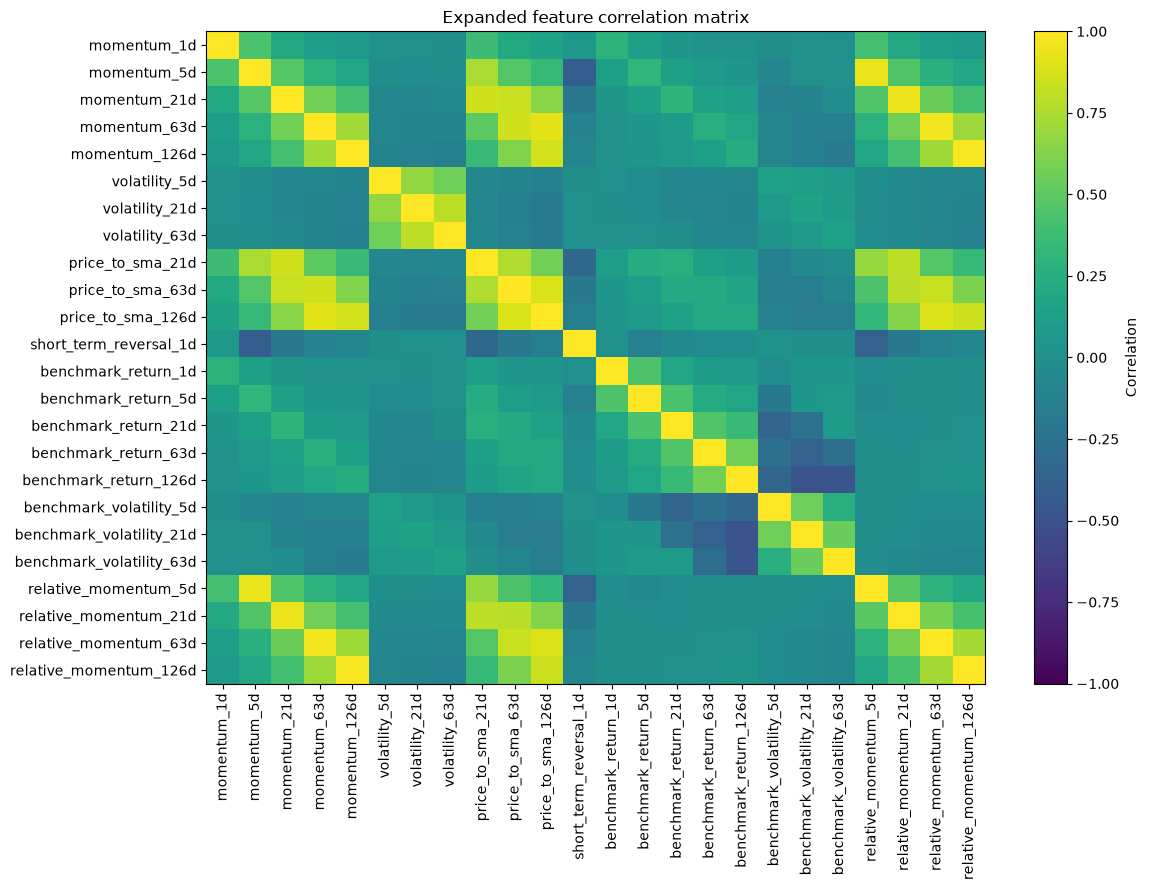

In [5]:
for h in [5, 21, 63, 126]:
    bench_col = f"benchmark_return_{h}d"
    stock_col = f"momentum_{h}d"
    if bench_col in prices.columns and stock_col in prices.columns:
        rel_col = f"relative_momentum_{h}d"
        prices[rel_col] = prices[stock_col] - prices[bench_col]
        all_feature_cols.append(rel_col)

feature_quality = pd.DataFrame({
    "feature": all_feature_cols,
    "missing_rate": [prices[c].isna().mean() for c in all_feature_cols],
    "unique_values": [prices[c].nunique(dropna=True) for c in all_feature_cols],
    "std": [prices[c].std() for c in all_feature_cols]
}).sort_values("missing_rate")
display(feature_quality)
feature_quality.to_csv(OUT / "expanded_feature_quality.csv", index=False)

corr = prices[all_feature_cols].corr(numeric_only=True)
corr.to_csv(OUT / "expanded_feature_correlation.csv")
fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index))); ax.set_yticklabels(corr.index)
ax.set_title("Expanded feature correlation matrix")
fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.savefig(OUT / "expanded_feature_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Merge features with corrected targets and endpoint metadata

In [6]:
target_table = pd.concat([
    pd.read_csv(PROJECT_ROOT / TRAIN_REL, low_memory=False),
    pd.read_csv(PROJECT_ROOT / VALID_REL, low_memory=False),
    pd.read_csv(PROJECT_ROOT / TEST_REL, low_memory=False)
], ignore_index=True)
target_table.columns = [str(c).strip().lower() for c in target_table.columns]
target_table["ticker"] = target_table["ticker"].astype(str).str.strip().str.upper()
target_table["date"] = pd.to_datetime(target_table["date"], errors="coerce")
target_table["target_endpoint_date_3m"] = pd.to_datetime(target_table["target_endpoint_date_3m"], errors="coerce")
target_table["forward_return_3m"] = pd.to_numeric(target_table["forward_return_3m"], errors="coerce")

feature_table = prices[["ticker", "date"] + all_feature_cols].copy()
feature_table = feature_table.drop_duplicates(["ticker", "date"], keep="last")
model_table = target_table.merge(
    feature_table, on=["ticker", "date"], how="left", validate="one_to_one"
)
model_table = model_table.dropna(subset=["forward_return_3m", "target_endpoint_date_3m"]).copy()
model_table.to_csv(FEATURE_OUT / "asx_3m_expanded_features_targets.csv", index=False)
print("Expanded model table:", model_table.shape)
print("Target coverage:", model_table["forward_return_3m"].notna().mean())

Expanded model table: (55943, 38)
Target coverage: 1.0


## 7. Reuse fixed chronological split dates and compare validation performance

To avoid selecting features using the test period, use the exact date boundaries from Phase 13. The model is fitted on the original training era and evaluated on the original validation era. No test metrics are used for selection.

In [7]:
train_dates = pd.to_datetime(pd.read_csv(PROJECT_ROOT / TRAIN_REL)["date"], errors="coerce")
valid_dates = pd.to_datetime(pd.read_csv(PROJECT_ROOT / VALID_REL)["date"], errors="coerce")
test_dates = pd.to_datetime(pd.read_csv(PROJECT_ROOT / TEST_REL)["date"], errors="coerce")

train_end = train_dates.max()
valid_start = valid_dates.min()
valid_end = valid_dates.max()
test_start = test_dates.min()

train_exp = model_table[
    (model_table["date"] <= train_end) &
    (model_table["target_endpoint_date_3m"] < valid_start)
].copy()
valid_exp = model_table[
    (model_table["date"] >= valid_start) &
    (model_table["date"] <= valid_end) &
    (model_table["target_endpoint_date_3m"] < test_start)
].copy()

# Use the original test split only for row count and final fixed boundary; do not score it in this phase.
print("Expanded train/validation rows:", len(train_exp), len(valid_exp))
print("Train endpoint max:", train_exp["target_endpoint_date_3m"].max())
print("Validation endpoint max:", valid_exp["target_endpoint_date_3m"].max())
print("Validation start:", valid_start, "| Test start:", test_start)
assert train_exp["target_endpoint_date_3m"].max() < valid_start
assert valid_exp["target_endpoint_date_3m"].max() < test_start

Expanded train/validation rows: 40447 6084
Train endpoint max: 2025-02-17 00:00:00
Validation endpoint max: 2025-10-31 00:00:00
Validation start: 2025-02-18 00:00:00 | Test start: 2025-11-03 00:00:00


## 8. Compare baseline and expanded-feature models on validation

,model,n_features,n_validation,MAE,RMSE,R2,actual_mean,predicted_mean
0,Expanded Ridge,19,6084,0.141023,0.195802,-0.089408,0.075098,0.029378
1,Training mean baseline,19,6084,0.141984,0.195113,-0.081749,0.075098,0.021461
2,Expanded Random Forest,19,6084,0.148972,0.209516,-0.247350,0.075098,0.032391


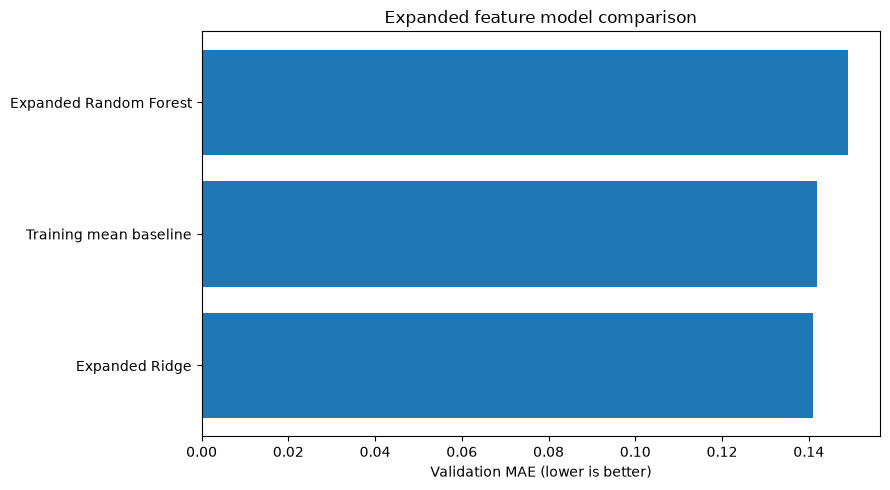

In [8]:
# Keep only features with at least some non-missing training values.
usable_features = [
    c for c in all_feature_cols
    if c in train_exp.columns and train_exp[c].notna().any()
]
if not usable_features:
    raise ValueError("No usable expanded features in training split.")

Xtr, ytr = train_exp[usable_features], train_exp["forward_return_3m"].astype(float)
Xva, yva = valid_exp[usable_features], valid_exp["forward_return_3m"].astype(float)

models = {
    "Training mean baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyRegressor(strategy="mean"))
    ]),
    "Expanded Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10.0))
    ]),
    "Expanded Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=250, min_samples_leaf=25, max_features=0.8,
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

validation_rows = []
for name, model in models.items():
    model.fit(Xtr, ytr)
    p = model.predict(Xva)
    validation_rows.append({
        "model": name, "n_features": len(usable_features),
        "n_validation": len(yva),
        "MAE": mean_absolute_error(yva, p),
        "RMSE": np.sqrt(mean_squared_error(yva, p)),
        "R2": r2_score(yva, p),
        "actual_mean": yva.mean(), "predicted_mean": np.mean(p)
    })
validation_results = pd.DataFrame(validation_rows).sort_values("MAE").reset_index(drop=True)
display(validation_results)
validation_results.to_csv(OUT / "expanded_feature_validation_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
plot_df = validation_results.sort_values("MAE")
ax.barh(plot_df["model"], plot_df["MAE"])
ax.set_xlabel("Validation MAE (lower is better)")
ax.set_title("Expanded feature model comparison")
plt.tight_layout()
plt.savefig(OUT / "expanded_feature_validation_mae.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Save Phase 19 summary

In [9]:
best_row = validation_results.iloc[0].to_dict()
baseline_row = validation_results[validation_results["model"] == "Training mean baseline"].iloc[0]
summary = {
    "phase": 19,
    "price_column_used": price_col,
    "price_rows": int(len(prices)),
    "tickers": int(prices["ticker"].nunique()),
    "features_created": all_feature_cols,
    "usable_features": usable_features,
    "train_rows": int(len(train_exp)),
    "validation_rows": int(len(valid_exp)),
    "test_rows_scored": 0,
    "validation_comparison": validation_results.to_dict(orient="records"),
    "best_validation_model": str(best_row["model"]),
    "best_validation_mae": float(best_row["MAE"]),
    "baseline_validation_mae": float(baseline_row["MAE"]),
    "best_beats_baseline": bool(best_row["MAE"] < baseline_row["MAE"]),
    "warning": "Validation-only exploratory feature assessment. Do not select features using test performance; verify point-in-time availability."
}
with open(OUT / "phase19_feature_expansion_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))
print("\nOutputs saved to:", OUT)

{
  "phase": 19,
  "price_column_used": "close",
  "price_rows": 65771,
  "tickers": 52,
  "features_created": [
    "momentum_1d",
    "momentum_5d",
    "momentum_21d",
    "momentum_63d",
    "momentum_126d",
    "volatility_5d",
    "volatility_21d",
    "volatility_63d",
    "price_to_sma_21d",
    "price_to_sma_63d",
    "price_to_sma_126d",
    "short_term_reversal_1d",
    "benchmark_return_1d",
    "benchmark_return_5d",
    "benchmark_return_21d",
    "benchmark_return_63d",
    "benchmark_return_126d",
    "benchmark_volatility_5d",
    "benchmark_volatility_21d",
    "benchmark_volatility_63d",
    "relative_momentum_5d",
    "relative_momentum_21d",
    "relative_momentum_63d",
    "relative_momentum_126d"
  ],
  "usable_features": [
    "momentum_1d",
    "momentum_5d",
    "momentum_126d",
    "volatility_5d",
    "volatility_21d",
    "volatility_63d",
    "price_to_sma_21d",
    "price_to_sma_63d",
    "price_to_sma_126d",
    "short_term_reversal_1d",
    "benchmark_r

## 10. Completion checklist

- Confirm feature construction completed without errors.
- Review missingness and correlation reports.
- Check the validation comparison against the mean baseline.
- Do not evaluate or tune against the test set in this phase.
- If the expanded features do not beat the baseline, consider refining the target definition or presenting the negative result transparently.